In [16]:
"""
Double Cover logo generator.

A curve that winds twice around a circle, floating above it, drawn from an
oblique viewpoint with honest self-occlusion. Writes a plain SVG file
(no dependencies beyond the standard library).

    python double_cover_logo.py                       # writes double_cover.svg
    python double_cover_logo.py --elev 20 -o logo.svg
    python double_cover_logo.py --size 32 --favicon -o favicon-32.svg

In a Jupyter notebook, skip the command line and call the functions:

    from IPython.display import SVG, display
    svg = save_svg("double_cover.svg")            # writes the file, returns the text
    display(SVG(svg))
"""
import argparse
import math

# --------------------------------------------------------------------------- the curve
HEIGHT = 0.70      # mean height of the strand above the floor circle
SWING = 0.48       # how far the two laps are separated vertically


def curve(t):
    """t in [0, 4*pi): two laps around the unit circle; the height oscillates
    at half speed, so above every point of the circle sit two points."""
    return (math.cos(t), math.sin(t), HEIGHT + SWING * math.cos(t / 2))


# --------------------------------------------------------------------------- the view
def make_projector(az, el, cx, cy, scale):
    ca, sa, ce, se = math.cos(az), math.sin(az), math.cos(el), math.sin(el)

    def proj(p):
        x, y, z = p
        X = x * ca - y * sa
        Y = x * sa + y * ca
        sx = cx + scale * X
        sy = cy - scale * (z * ce + Y * se)
        depth = -Y * ce + z * se            # larger = nearer the viewer
        return sx, sy, depth
    return proj


def seg_intersect(a, b, c, d):
    r1, r2 = b[0] - a[0], b[1] - a[1]
    s1, s2 = d[0] - c[0], d[1] - c[1]
    den = r1 * s2 - r2 * s1
    if abs(den) < 1e-12:
        return None
    u = ((c[0] - a[0]) * s2 - (c[1] - a[1]) * s1) / den
    v = ((c[0] - a[0]) * r2 - (c[1] - a[1]) * r1) / den
    eps = 1e-6
    if -eps <= u <= 1 + eps and -eps <= v <= 1 + eps:
        return u, v
    return None


# --------------------------------------------------------------------------- drawing
def build_svg(elev_deg=28.6, az_deg=-31.5, width=200, height=170, line=4.5,
              depth_amp=0.75, gap=1.8, floor=1.2, floor_opacity=0.55,
              min_run=18.0, color="#000000", n=901, favicon=False):
    el, az = math.radians(elev_deg), math.radians(az_deg)
    cx, scale = width / 2, 64 * width / 200
    # keep the drawing vertically centred as the viewpoint drops
    cy = (114 + (0.5 - el) * 33) * width / 200
    proj = make_projector(az, el, cx, cy, scale)

    if favicon:  # heavier lines for tiny sizes
        line, floor, gap, depth_amp = line * 2.2, floor * 3.3, gap * 1.4, 0.6

    # floor ring
    ring = [proj((math.cos(2 * math.pi * i / 160), math.sin(2 * math.pi * i / 160), 0))
            for i in range(161)]
    ring_d = "M" + " L".join(f"{x:.2f},{y:.2f}" for x, y, _ in ring)

    # strand, sampled
    P = [proj(curve(4 * math.pi * (i + 0.37) / n)) for i in range(n)]
    dmin, dmax = min(p[2] for p in P), max(p[2] for p in P)
    W = [line * (1 + depth_amp * ((p[2] - dmin) / (dmax - dmin) - 0.5)) for p in P]
    nx = lambda i: (i + 1) % n
    L = lambda i: math.hypot(P[nx(i)][0] - P[i][0], P[nx(i)][1] - P[i][1])

    # find crossings; break only the strand further from the viewer
    hide = [False] * n
    seen = []
    for i in range(n):
        for j in range(i + 10, n):
            if n - (j - i) < 10:
                continue
            r = seg_intersect(P[i], P[nx(i)], P[j], P[nx(j)])
            if not r:
                continue
            x = P[i][0] + r[0] * (P[nx(i)][0] - P[i][0])
            y = P[i][1] + r[0] * (P[nx(i)][1] - P[i][1])
            if any(math.hypot(qx - x, qy - y) < 6 for qx, qy in seen):
                continue
            seen.append((x, y))
            di = P[i][2] + r[0] * (P[nx(i)][2] - P[i][2])
            dj = P[j][2] + r[1] * (P[nx(j)][2] - P[j][2])
            if abs(di - dj) < 0.05:      # the laps genuinely meet here: first lap goes under
                under = i
            else:
                under = j if dj < di else i
            over = j if under == i else i
            half = W[over] / 2 + W[under] / 2 + gap
            for step in (1, -1):
                acc, k = 0.0, under if step == 1 else (under - 1) % n
                while acc < half:
                    hide[k] = True
                    acc += L(k)
                    k = (k + step) % n

    # remove visible slivers too short to read as line
    if any(hide):
        i = hide.index(True)
        count = 0
        while count < n:
            if not hide[i]:
                j, length, steps = i, 0.0, 0
                while not hide[j] and steps < n:
                    length += L(j)
                    j = nx(j)
                    steps += 1
                if length < min_run:
                    k = i
                    for _ in range(steps):
                        hide[k] = True
                        k = nx(k)
                count += steps
                i = j
            else:
                i = nx(i)
                count += 1

    # draw back to front, width varying with depth
    segs = [i for i in range(n) if not hide[i] and not hide[nx(i)]]
    segs.sort(key=lambda i: P[i][2])

    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
           f'width="{width}" height="{height}">',
           f'<path d="{ring_d}" fill="none" stroke="{color}" stroke-width="{floor:.2f}" '
           f'opacity="{floor_opacity}"/>',
           f'<g stroke="{color}" stroke-linecap="round">']
    for i in segs:
        k = nx(i)
        out.append(f'<line x1="{P[i][0]:.2f}" y1="{P[i][1]:.2f}" x2="{P[k][0]:.2f}" '
                   f'y2="{P[k][1]:.2f}" stroke-width="{(W[i] + W[k]) / 2:.2f}"/>')
    out.append("</g></svg>")
    return "\n".join(out)


def save_svg(path="double_cover.svg", size=200, **kwargs):
    """Write the logo to `path`. Handy from a notebook:
        save_svg("logo.svg", elev_deg=20)
        save_svg("favicon-32.svg", size=32, favicon=True)
    """
    svg = build_svg(**kwargs)
    if size != 200:  # change the displayed size; geometry stays in the 200x170 box
        svg = svg.replace('width="200" height="170"', f'width="{size}" height="{round(size*170/200)}"', 1)
    with open(path, "w") as f:
        f.write(svg)
    return svg


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description=__doc__, allow_abbrev=False,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("-o", "--out", default="double_cover.svg")
    ap.add_argument("--elev", type=float, default=22.6, help="viewing elevation above the floor, degrees")
    ap.add_argument("--az", type=float, default=-31.5, help="viewing azimuth, degrees")
    ap.add_argument("--line", type=float, default=4.5, help="strand width")
    ap.add_argument("--color", default="#000000")
    ap.add_argument("--size", type=int, default=200, help="output width in px (height keeps 200:170)")
    ap.add_argument("--favicon", action="store_true", help="heavier lines for tiny sizes")
    a, _ = ap.parse_known_args()   # ignore extra args, e.g. Jupyter's "-f kernel.json"
    save_svg(a.out, size=a.size, elev_deg=a.elev, az_deg=a.az, line=a.line,
             color=a.color, favicon=a.favicon)
    print(f"wrote {a.out}")

wrote double_cover.svg


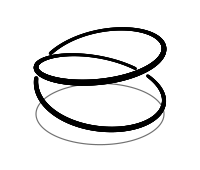

'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 200 170" width="32" height="27">\n<path d="M154.57,130.03 L155.84,129.00 L157.02,127.94 L158.12,126.85 L159.13,125.75 L160.04,124.63 L160.87,123.49 L161.60,122.34 L162.23,121.18 L162.77,120.00 L163.21,118.82 L163.56,117.63 L163.80,116.43 L163.95,115.23 L164.00,114.03 L163.95,112.82 L163.80,111.62 L163.56,110.43 L163.21,109.24 L162.77,108.05 L162.23,106.88 L161.60,105.71 L160.87,104.56 L160.04,103.42 L159.13,102.30 L158.12,101.20 L157.02,100.12 L155.84,99.06 L154.57,98.02 L153.21,97.01 L151.78,96.02 L150.26,95.06 L148.67,94.13 L147.00,93.23 L145.25,92.36 L143.44,91.53 L141.56,90.73 L139.62,89.97 L137.62,89.24 L135.56,88.55 L133.44,87.91 L131.27,87.30 L129.06,86.73 L126.79,86.21 L124.49,85.72 L122.15,85.28 L119.78,84.89 L117.37,84.54 L114.94,84.24 L112.49,83.98 L110.01,83.77 L107.52,83.60 L105.02,83.49 L102.51,83.41 L100.00,83.39 L97.49,83.41 L94.98,83.49 L92.48,83.60 L89.99,83.77 L87.51,83.98 L85.06,84.24 L82.63,84.54 L80.22,84.89 L7

In [ ]:
from IPython.display import SVG, display

svg = save_svg("double_cover.svg")                 # writes the file, returns the SVG text
display(SVG(svg))

save_svg("logo_30deg.svg", elev_deg=30)            # any option as a keyword
save_svg("favicon-32.svg", size=32, favicon=True)